In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import os
sys.path.append('../../')
from utils.Evaluation.calculate_metrics_eleftheria import calculate_scores_mageirema, calculate_scores_benchmark, calculate_scores, calculate_scores_qachain
import seaborn as sns
sns.set_style(style='whitegrid')  # Better background

In [2]:
def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

def calculate_metrics(model_name, dataset, path):
    df = pd.read_excel(path)

    # df.rename(columns={'generated_cypher': 'Generated_Cypher'}, inplace=True)

    #Calcultes the metrics and saved the the df with the results and the evaluation metrics
    df = calculate_scores_qachain(model_name, dataset, df)

    # df['error_codes'] = df['cypher_errors_history'].apply(extract_error_types)

    return df

def extract_dfs(df):

    kg_valid_queries_df = df[df['is_KG_Valid_correct']==True].reset_index(drop=True)
    unavailable_output_df = df[df['answer']=="I couldn't find any relevant information in the database"].reset_index(drop=True)
    kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema']==True].reset_index(drop=True)
    kg_valid_queries_with_filtered_schema_df = df[(df['is_KG_Valid_correct_with_full_schema']==False) & (df['is_KG_Valid_correct']==True)].reset_index(drop=True)

    return kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df

# Calculate Scores in dfs

In [ ]:
# SustainDataset
dataset = 'SustainDataset'
models =['gpt_4o']
for model_name in models:
    path = f'../Results/{dataset}/{model_name}/{model_name}.xlsx'
    df = calculate_metrics(model_name, dataset,path)

  0%|          | 0/47 [00:00<?, ?it/s]

0 neo4jcopy


/home/eleftheria/agentic-text-2-cypher/venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/home/eleftheria/agentic-text-2-cypher/venv/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


OSError: Cannot save file into a non-existent directory: 'SustainDataset/gpt_4o/QAChain'

In [13]:
df

,Level,Sublevel,Level of Difficulty,Topic,Question,"Cypher query ( Single Match, integrated properties)","Cypher query 2 (Single Match, Where)","Cypher query 3 (Multiple Match, integrated properties)","Cypher query 4 (Multiple Match,Where)",Alternative query,...,Properties Valid,Properties Metadata,Pass@1 Output,Jaccard Output,BLEU,Rouge-L Precision,Rouge-L Recall,Rouge-L F1-score,Jaro Similarity,Jaccard Similarity
0,Level A: Explict Facts,Sublevel 1:Nodes,Easy,SDG,What is the title of the goal with code 2?,MATCH (n:Goal{code : '2' })RETURN n.title,MATCH (n:Goal) WHERE n.code = '2' RETURN n.title,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,3.912950e-01,0.75,0.75,0.75,0.968000,0.555556
1,Level A: Explict Facts,Sublevel 1:Nodes,Easy,GeoArea,Which is the EUcode for the geoarea with name ...,MATCH (g:GeoArea{name:'Greece'}) RETURN g.EUcode,MATCH (g:GeoArea) WHERE g.name='Greece' RETURN...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,8.003203e-01,1.00,1.00,1.00,0.986441,0.750000
2,Level A: Explict Facts,Sublevel 1:Nodes,Easy,GeoArea,Which is the name of the area that has the EUc...,MATCH (a:Area{EUcode: 'FR'}) RETURN a.name,MATCH (a:Area) WHERE a.EUcode= 'FR' RETURN a....,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000
3,Level A: Explict Facts,Sublevel 1:Nodes,Easy,CS,Which is the title of case study with code cs_1?,MATCH (c:CaseStudy{code:'cs_1'}) RETURN c.title,MATCH (c:CaseStudy) WHERE c.code = 'cs_1' RETU...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,6.389431e-01,0.78,0.78,0.78,0.951954,0.750000
4,Level A: Explict Facts,Sublevel 1:Nodes,Easy,Hazard,Which are the hazards names with Environmental...,MATCH (h:Hazard{type:'Environmental'})\nRETURN...,MATCH (h:Hazard) WHERE h.type = 'Environmental...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,8.003203e-01,1.00,1.00,1.00,0.987302,0.750000
5,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Target, SDG",What are the target codes that goal with code ...,MATCH (n:Goal{code: '8' })-[:HAS_TARGET]->(t:T...,MATCH (n:Goal)-[:HAS_TARGET]->(t:Target)\nWHER...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,9.057663e-01,0.92,0.92,0.92,0.995349,0.800000
6,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Indicator, Series",Which are the series' code and description tha...,MATCH (i:Indicator{code:'vulnerability'})-[:HA...,MATCH (i:Indicator)-[:HAS_SERIES]->(s:Series)\...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000
7,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Indicator, PolicyTarget",Which indicator codes have EU policy targets ?,MATCH (i:Indicator)-[:HAS_POLICY_TARGET]->(:EU...,NaN,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000
8,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Typology, GeoArea",Which NUTS3 have typology island?,MATCH (n:NUTS3)-[HAS_TYPOLOGY]->(:Island) RETU...,NaN,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,6.149273e-01,0.73,1.00,0.84,0.894267,0.750000
9,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Series, SeriesMetadata",Which are the dimensions code and description ...,MATCH (s:Series{code:'AG_LND_AGRWAG'})-[:HAS_M...,MATCH (s:Series)-[:HAS_METADATA]->(sm:SeriesMe...,NaN,NaN,NaN,...,1.0,[],1.0,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000


# KG Valid Queries

In [ ]:
# def extract_and_plot(models_dict, extract_dfs_func, max_cols=3, figsize=(15, 5)):
#     """
#     Extract data for multiple models and plot horizontal bar charts for each.
    
#     Parameters:
#     - models_dict: A dictionary with keys the model names and the dfs with the calculated metrics
#     - extract_dfs_func: function(path) returning (kg_valid_queries_df, unavailable_output_df, 
#                                                kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df)
#     - max_cols: maximum number of columns in subplot grid
#     - figsize: size of figure, width will scale with columns
    
#     Supports any number of models.
#     """
#     all_values_orig, all_values_pass, all_labels, all_thresholds, all_names = [], [], [], [], []

#     models = models_dict.keys()

#     for model_name in models_dict:
#         df = models_dict[model_name]
#         kg_valid_queries_df, unavailable_output_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df = extract_dfs_func(df)
        
#         # Original counts
#         kg_valid_queries = len(kg_valid_queries_df)
#         kg_valid_queries_with_full_schema = len(kg_valid_queries_with_full_schema_df)
#         kg_valid_queries_with_filtered_schema = kg_valid_queries - kg_valid_queries_with_full_schema
#         unavailable_output = len(unavailable_output_df)
#         threshold = len(df)

#         # Filtered counts where df['pass'] == True
#         kg_valid_queries_pass = len(kg_valid_queries_df[kg_valid_queries_df['Pass@1 Output']==True])
#         kg_valid_queries_with_full_schema_pass = len(kg_valid_queries_with_full_schema_df[kg_valid_queries_with_full_schema_df['Pass@1 Output']==True])
#         kg_valid_queries_with_filtered_schema_pass = len(kg_valid_queries_with_filtered_schema_df[kg_valid_queries_with_filtered_schema_df['Pass@1 Output']==True])
#         unavailable_output_pass = 0
        
#         # Values for original bars and pass-filtered bars
#         values_orig = [unavailable_output, kg_valid_queries, kg_valid_queries_with_full_schema, kg_valid_queries_with_filtered_schema]
#         values_pass = [unavailable_output_pass, kg_valid_queries_pass, kg_valid_queries_with_full_schema_pass, kg_valid_queries_with_filtered_schema_pass]
#         labels = ['Unavailable Output', 'KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']
        
#         all_values_orig.append(values_orig)
#         all_values_pass.append(values_pass)
#         all_labels.append(labels)
#         all_thresholds.append(threshold)
#         all_names.append(model_name)
    
#     n_plots = len(models)
#     n_cols = min(max_cols, n_plots)
#     n_rows = math.ceil(n_plots / n_cols)
#     fig_width = figsize[0] * n_cols / max_cols
#     fig_height = figsize[1] * n_rows
    
#     fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), squeeze=False)
#     axes_flat = axes.flatten()
    
#     def plot_barh(ax, values_orig, values_pass, labels, threshold, model_name):
#         # Bar width and positions for grouped bars
#         y_pos = np.arange(len(labels))
#         bar_height = 0.35
        
#         # Plot original bars
#         ax.barh(y_pos - bar_height/2, values_orig, height=bar_height, color='skyblue', label='KG Valid')
#         # Plot pass==True bars next to original
#         ax.barh(y_pos + bar_height/2, values_pass, height=bar_height, color='lightgreen', label='Pass=True')
        
#         # Add values and percentages text
#         for i, (val_o, val_p) in enumerate(zip(values_orig, values_pass)):
#             pct_o = (val_o / threshold) * 100 if threshold > 0 else 0
#             pct_p = (val_p / threshold) * 100 if threshold > 0 else 0
#             ax.text(val_o + 0.5, i - bar_height/2, f'{val_o} ({pct_o:.0f}%)', va='center', fontsize=9)
#             ax.text(val_p + 0.5, i + bar_height/2, f'{val_p} ({pct_p:.0f}%)', va='center', fontsize=9)
        
#         ax.set_yticks(y_pos)
#         ax.set_yticklabels(labels)
#         ax.axvline(x=threshold, color='red', linestyle='--', label='Threshold')
#         ax.set_xlabel('Value')
#         ax.set_title(model_name.title())
#         ax.legend()
#         ax.set_xticks(np.arange(0, threshold + 5, max(1, threshold // 10) if threshold > 10 else 1))
    
#     for i in range(n_plots):
#         plot_barh(axes_flat[i], all_values_orig[i], all_values_pass[i], all_labels[i], all_thresholds[i], all_names[i])
    
#     # Hide unused axes if any
#     for j in range(n_plots, len(axes_flat)):
#         axes_flat[j].axis('off')
    
#     plt.tight_layout(w_pad=4, h_pad=4)
#     plt.show()


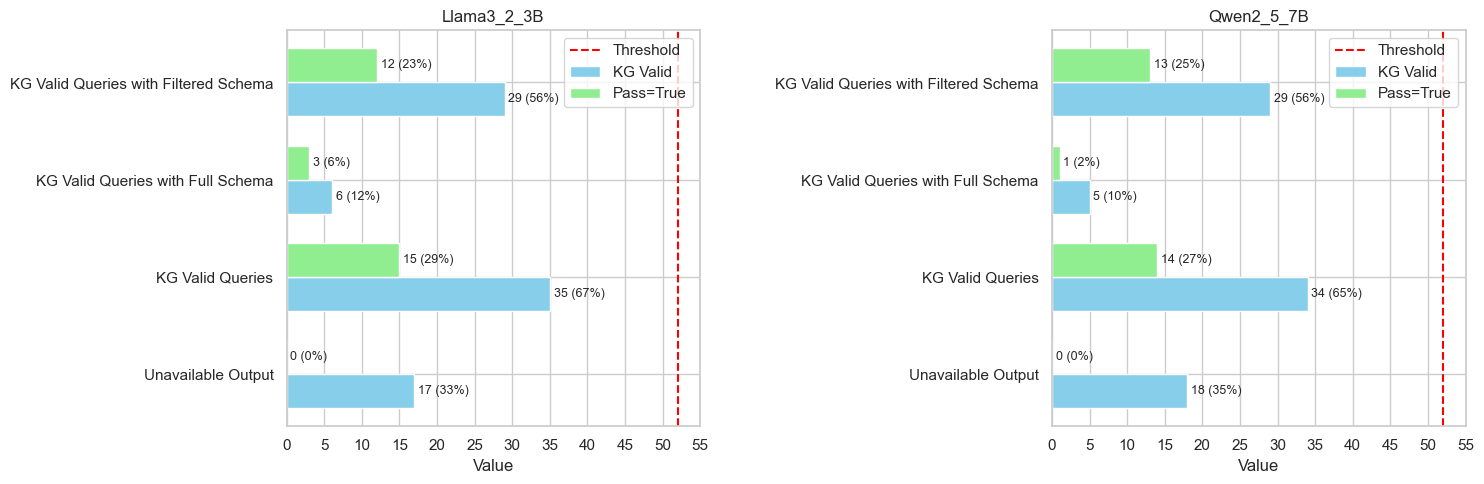

In [ ]:
# extract_and_plot(dfs_dict,extract_dfs,2)  # For two plots

C:\Users\ioann\AppData\Local\Temp\ipykernel_29280\431025141.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


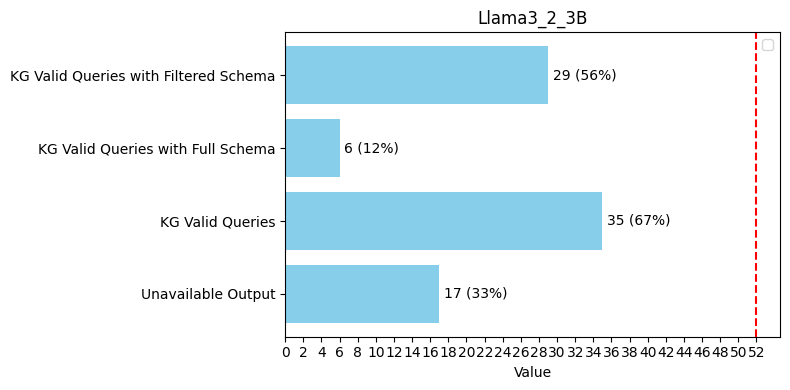

In [ ]:
# model_name = 'llama3_2_3b'
# path = './Results/SustainDataset/' + model_name + '/' + model_name +'.pkl'

# df = dfs_dict[model_name]
# kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df= extract_dfs(dfs_dict[model_name])

# kg_valid_queries = len(kg_valid_queries_df)
# kg_valid_queries_with_full_schema = len(kg_valid_queries_with_full_schema_df)
# kg_valid_queries_with_filtered_schema = kg_valid_queries - kg_valid_queries_with_full_schema
# unavailable_output = len(unavailable_output_df)

# # Data
# values = [unavailable_output,kg_valid_queries, kg_valid_queries_with_full_schema, kg_valid_queries_with_filtered_schema]
# labels = ['Unavailable Output','KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']
# threshold = len(df)

# # Calculate percentages relative to threshold
# percentages = [(v / threshold) * 100 for v in values]

# plt.figure(figsize=(8, 4))
# plt.barh(labels, values, color='skyblue')
# plt.axvline(x=threshold, color='red', linestyle='--')

# # Add combined text: "Value (xx%)"
# for i, (label, value) in enumerate(zip(labels, values)):
#     pct = percentages[i]
#     label_text = f'{value} ({pct:.0f}%)'
#     plt.text(value + 0.5, i, label_text, va='center', fontsize=10)

# # Formatting
# plt.xticks(np.arange(0, len(df) + 2, 2))
# plt.xlabel('Value')
# plt.title(model_name.title())
# plt.legend()
# plt.tight_layout()
# plt.show()


# Unavailable output

In [ ]:
# # model_name = 'llama3_2_3b'
# model_name = 'qwen2_5_7b'
# path = './Results/SustainDataset/' + model_name + '/' + model_name +'.pkl'

# df = dfs_dict[model_name]
# kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df= extract_dfs(dfs_dict[model_name])

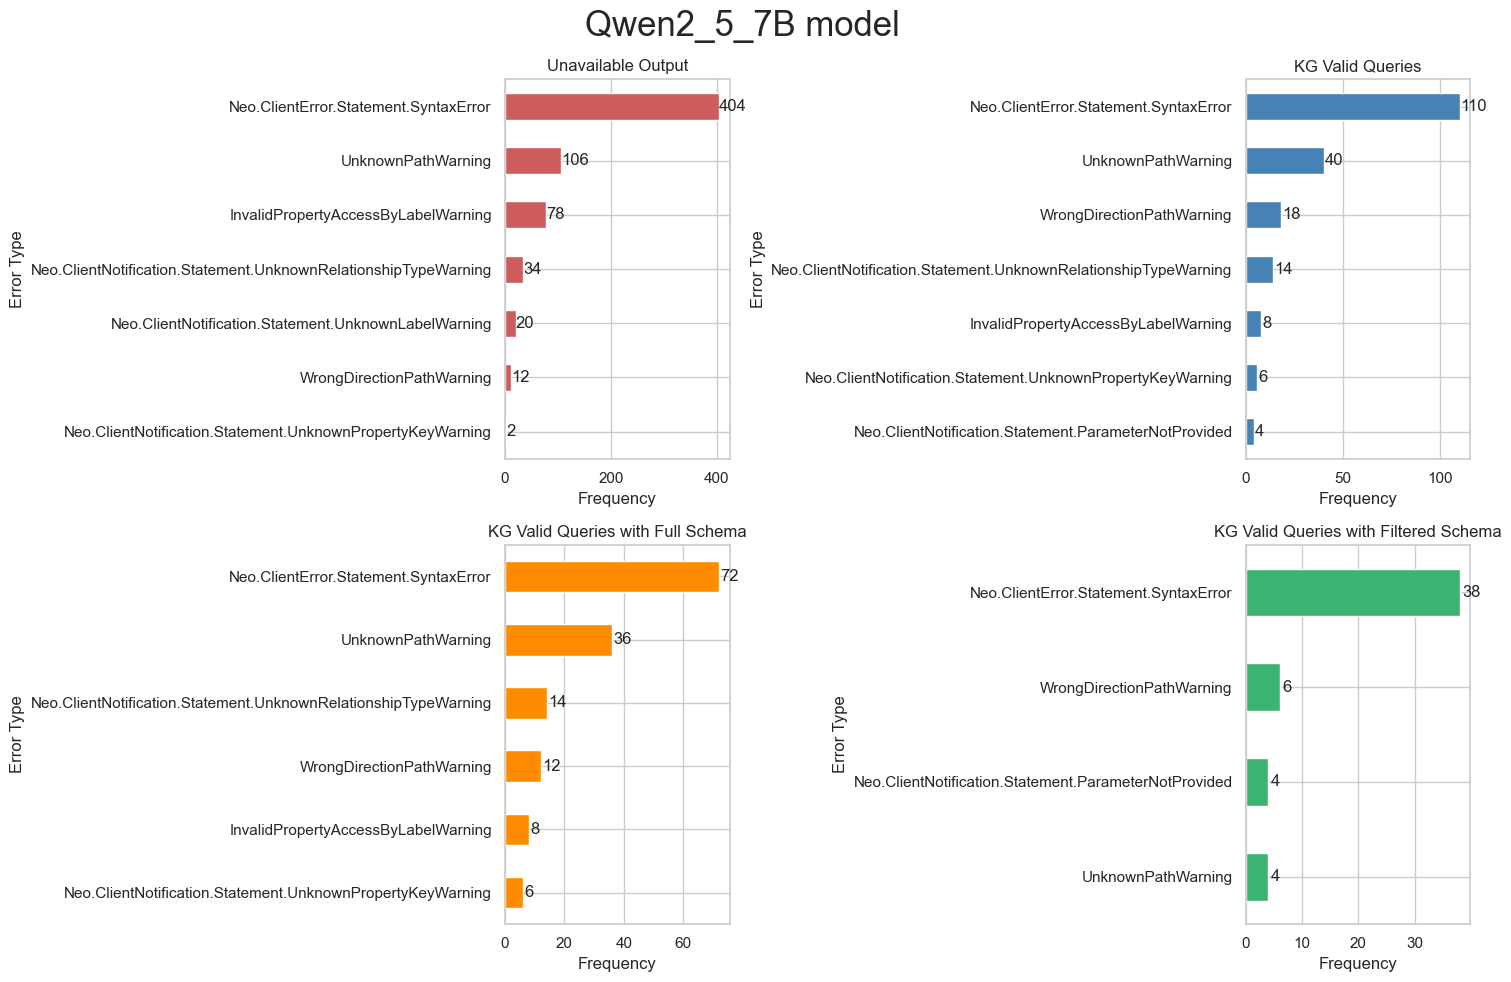

In [ ]:
# # Example: your 4 DataFrames
# dfs = [unavailable_output_df,kg_valid_queries_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df]
# labels = ['Unavailable Output','KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']

# # Colors for each plot
# colors = ['indianred','steelblue', 'darkorange', 'mediumseagreen']

# fig, axes = plt.subplots(2, 2, figsize=(15, 10))  # 2x2 grid
# axes = axes.flatten()  # Flatten to 1D for easy looping

# for i, (df, color, ax) in enumerate(zip(dfs, colors, axes)):
#     # Flatten and count error_types frequency
#     error_counts = pd.Series(
#         [err for sublist in df['error_codes'] for err in sublist]
#     ).value_counts()

#     # Plot horizontal bar chart
#     error_counts.plot(kind='barh', color=color, ax=ax)

#     # Add counts to bars
#     for j, (label, count) in enumerate(error_counts.items()):
#         ax.text(count + 0.5, j, str(count), va='center')

#     ax.set_title(labels[i])
#     ax.set_xlabel('Frequency')
#     ax.set_ylabel('Error Type')
#     ax.invert_yaxis()  # Highest frequency on top
# fig.suptitle(model_name.title() + ' model',size=25)
# plt.tight_layout()
# plt.show()

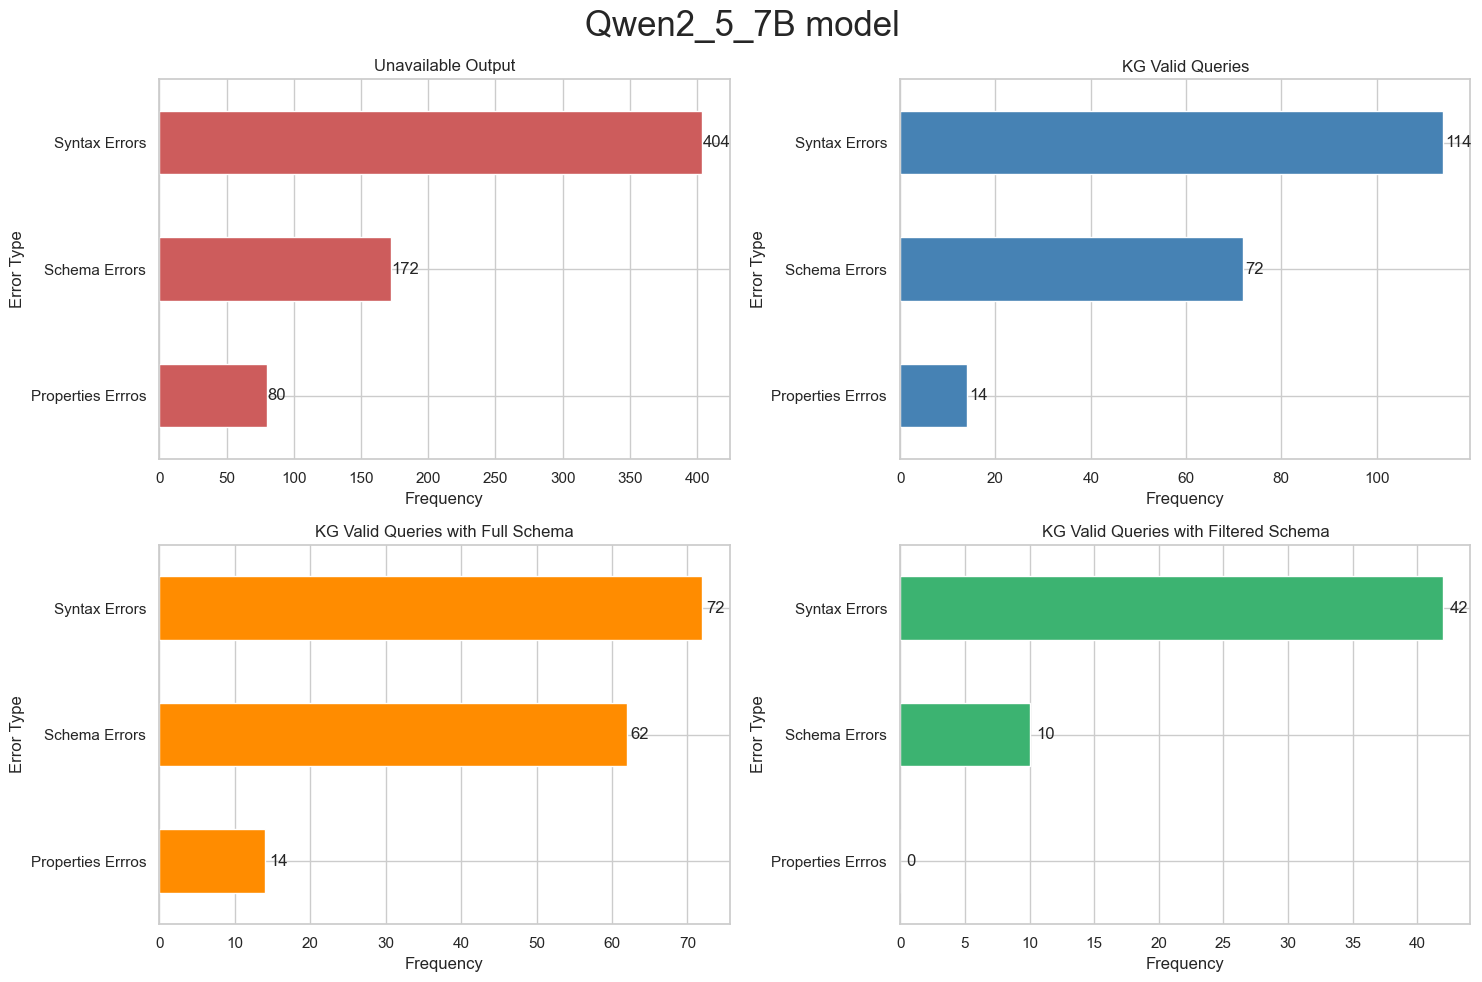

In [ ]:
# schema_errors = ['Neo.ClientNotification.Statement.UnknownLabelWarning',
#                 'Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning',
#                 'UnknownPathWarning',
#                 'WrongDirectionPathWarning',
#                 'VariableLengthPathWarning',
#                 'WrongDirectionPath&VariableLengthPathWarning']
# properties_errors= ['Neo.ClientNotification.Statement.UnknownPropertyKeyWarning','InvalidPropertyAccessByLabelWarning']

# # Example: your 4 DataFrames
# dfs = [unavailable_output_df,kg_valid_queries_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df]
# labels = ['Unavailable Output','KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']


# # Colors for each plot
# colors = ['indianred','steelblue', 'darkorange', 'mediumseagreen']

# fig, axes = plt.subplots(2, 2, figsize=(15, 10))  # 2x2 grid
# axes = axes.flatten()  # Flatten to 1D for easy looping

# for i, (df, color, ax) in enumerate(zip(dfs, colors, axes)):
#     # Flatten and count error_types frequency
#     error_counts = pd.Series(
#         [err for sublist in df['error_codes'] for err in sublist]
#     ).value_counts()

#     schema_errors_count = error_counts[error_counts.index.isin(schema_errors)].sum()
#     properties_errors_count = error_counts[error_counts.index.isin(properties_errors)].sum()

#     # Optional: collect in a dictionary or Series
#     category_sums = pd.Series({
#         'Syntax Errors': error_counts[~error_counts.index.isin(schema_errors + properties_errors)].sum(),
#         'Schema Errors': schema_errors_count,
#         'Properties Errros': properties_errors_count,
#     })

#     # Plot horizontal bar chart
#     category_sums.plot(kind='barh', color=color, ax=ax)

#     # Add counts to bars
#     for j, (label, count) in enumerate(category_sums.items()):
#         ax.text(count + 0.5, j, str(count), va='center')

#     ax.set_title(labels[i])
#     ax.set_xlabel('Frequency')
#     ax.set_ylabel('Error Type')
#     ax.invert_yaxis()  # Highest frequency on top
# fig.suptitle(model_name.title() + ' model',size=25)
# plt.tight_layout()
# plt.show()

# Retries

In [ ]:
# def count_value_between(lst, start, end, target):
#     i, j = lst.index(start), lst.index(end)
#     return lst[min(i, j) + 1 : max(i, j)].count(target)
# def count_tries_full(row):
#     path = row['path']
#     if 'schema_retriever' in path:
#         # kg valid
#         if 'output_generator' in path:
#             count = count_value_between(path, 'cypher_generator', 'output_generator', 'cyver_evaluator') - 6 
#         else:
#             count = count_value_between(path, 'cypher_generator', 'unavailable_output', 'cyver_evaluator')- 6
#     else:
#         count=None
#     return count

# def count_tries_filt(row):
#     path = row['path']
#     if 'schema_retriever' not in path:
#         count = count_value_between(path, 'cypher_generator', 'output_generator', 'cyver_evaluator')
    
#     else:
#         count=None 
#     return count

In [ ]:
# for model_name in dfs_dict:
#     df = dfs_dict[model_name]

#     df['Tries_with_Full_Schema'] = df.apply(count_tries_full, axis=1)
#     df['Tries_with_Filtered_Schema'] = df.apply(count_tries_filt, axis=1)

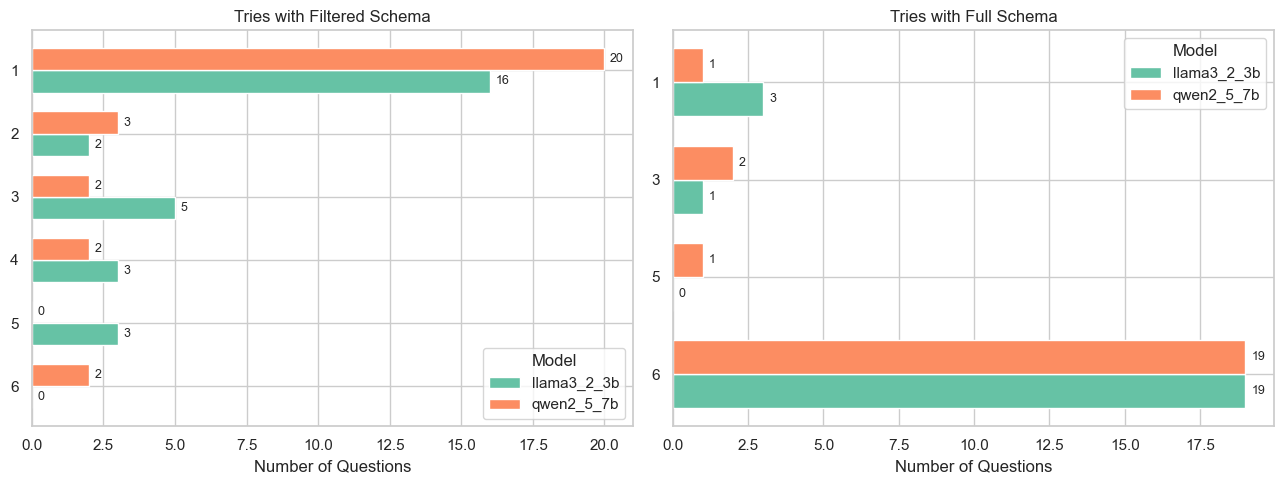

In [ ]:
# # Setup
# cols = ['Tries_with_Filtered_Schema', 'Tries_with_Full_Schema']
# bar_height = 0.35
# palette = sns.color_palette("Set2", n_colors=len(dfs_dict))  # Choose a good palette

# fig, ax = plt.subplots(1, len(cols), figsize=(13, 5))
# if len(cols) == 1:
#     ax = [ax]  # Ensure list-like

# # Apply schema-count functions once
# for df in dfs_dict.values():
#     df['Tries_with_Full_Schema'] = df.apply(count_tries_full, axis=1)
#     df['Tries_with_Filtered_Schema'] = df.apply(count_tries_filt, axis=1)

# labels = list(dfs_dict.keys())

# for i, col in enumerate(cols):
#     # Find all unique values across all models for this column
#     all_vals = pd.concat([df[col].dropna().astype(int) for df in dfs_dict.values()])
#     unique_vals = sorted(all_vals.unique(), reverse=True)
#     y_pos = range(len(unique_vals))

#     # Count frequencies
#     all_counts = [
#         df[col].dropna().astype(int).value_counts().reindex(unique_vals, fill_value=0)
#         for df in dfs_dict.values()
#     ]

#     # Plot bars side-by-side for each model
#     for j, counts in enumerate(all_counts):
#         offset = (j - len(all_counts)/2) * bar_height + bar_height/2
#         ax[i].barh(
#             [y + offset for y in y_pos],
#             counts,
#             height=bar_height,
#             color=palette[j],
#             label=labels[j]
#         )
#         for y, v in zip(y_pos, counts):
#             ax[i].text(v + 0.2, y + offset, str(v), va='center', fontsize=9)

#     ax[i].set_yticks(y_pos)
#     ax[i].set_yticklabels(unique_vals)
#     ax[i].set_xlabel('Number of Questions')
#     ax[i].set_title(col.replace('_', ' '))
#     ax[i].legend(title='Model', loc='best')

# plt.tight_layout()
# plt.show()

In [ ]:
# print(model_name)
# print('{} Retries with schema filtering'.format(df['Tries_with_Filtered_Schema'].sum()))
# print('{} Retries with schema retriever'.format(df['Tries_with_Full_Schema'].sum()))
# print('{} Retries with schema filtering'.format(df['Tries_with_Filtered_Schema'].mean()))
# print('{} Retries with schema retriever'.format(df['Tries_with_Full_Schema'].mean()))

qwen2_5_7b
52.0 Retries with schema filtering
126.0 Retries with schema retriever
1.793103448275862 Retries with schema filtering
5.478260869565218 Retries with schema retriever


In [ ]:
# print(model_name)
# print('{} Retries with schema filtering'.format(df['Tries_with_Filtered_Schema'].sum()))
# print('{} Retries with schema retriever'.format(df['Tries_with_Full_Schema'].sum()))
# print('{} Retries with schema filtering'.format(df['Tries_with_Filtered_Schema'].mean()))
# print('{} Retries with schema retriever'.format(df['Tries_with_Full_Schema'].mean()))

llama3_2_3b
62.0 Retries with schema filtering
120.0 Retries with schema retriever
2.1379310344827585 Retries with schema filtering
5.217391304347826 Retries with schema retriever


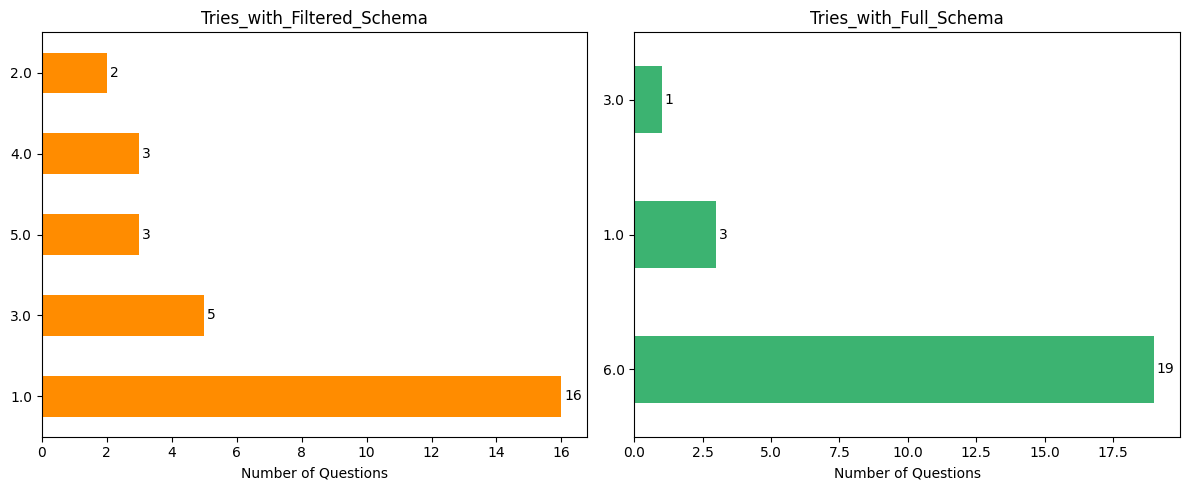

In [ ]:
# cols = ['Tries_with_Filtered_Schema', 'Tries_with_Full_Schema']
# fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# colors =['darkorange', 'mediumseagreen']

# for i, col in enumerate(cols):
#     counts = df[col].value_counts()
#     bars = counts.plot(kind='barh', ax=ax[i], title=col,color=colors[i])
#     for p in ax[i].patches:
#         ax[i].text(p.get_width() + 0.1, p.get_y() + p.get_height() / 2, int(p.get_width()), va='center')
#     ax[i].set_xlabel('Number of Questions')
#     ax[i].set_ylabel('')

# plt.tight_layout()
# plt.show()

# Pass@1

In [ ]:
# # model_name = 'llama3_2_3b'
# model_name = 'qwen2_5_7b'
# path = './Results/SustainDataset/' + model_name + '/' + model_name +'.pkl'

# df = dfs_dict[model_name]
# kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df= extract_dfs(dfs_dict[model_name])

In [ ]:
# kg_valid_queries_df

,Level,Sublevel,Level of Difficulty,Topic,Question,"Cypher query ( Single Match, integrated properties)","Cypher query 2 (Single Match, Where)","Cypher query 3 (Multiple Match, integrated properties)","Cypher query 4 (Multiple Match,Where)",Alternative query,...,Jaccard Output,BLEU,Rouge-L Precision,Rouge-L Recall,Rouge-L F1-score,Jaro Similarity,Jaccard Similarity,error_codes,Tries_with_Full_Schema,Tries_with_Filtered_Schema
0,Level A: Explict Facts,Sublevel 1:Nodes,Easy,SDG,What is the title of the goal with code 2?,MATCH (n:Goal{code : '2' })RETURN n.title,MATCH (n:Goal) WHERE n.code = '2' RETURN n.title,NaN,NaN,NaN,...,1.000000,6.389431e-01,0.75,0.75,0.75,0.984000,0.750000,[],NaN,1.0
1,Level A: Explict Facts,Sublevel 1:Nodes,Easy,GeoArea,Which is the EUcode for the geoarea with name ...,MATCH (g:GeoArea{name:'Greece'}) RETURN g.EUcode,MATCH (g:GeoArea) WHERE g.name='Greece' RETURN...,NaN,NaN,NaN,...,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000,"[Neo.ClientError.Statement.SyntaxError, Neo.Cl...",1.0,NaN
2,Level A: Explict Facts,Sublevel 1:Nodes,Easy,GeoArea,Which is the name of the area that has the EUc...,MATCH (a:Area{EUcode: 'FR'}) RETURN a.name,MATCH (a:Area) WHERE a.EUcode= 'FR' RETURN a....,NaN,NaN,NaN,...,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000,[],NaN,1.0
3,Level A: Explict Facts,Sublevel 1:Nodes,Easy,CS,Which is the title of case study with code cs_1?,MATCH (c:CaseStudy{code:'cs_1'}) RETURN c.title,MATCH (c:CaseStudy) WHERE c.code = 'cs_1' RETU...,NaN,NaN,NaN,...,0.023810,5.868136e-01,0.82,1.00,0.90,0.913096,0.875000,[],NaN,1.0
4,Level A: Explict Facts,Sublevel 1:Nodes,Easy,Hazard,Which are the hazards names with Environmental...,MATCH (h:Hazard{type:'Environmental'})\nRETURN...,MATCH (h:Hazard) WHERE h.type = 'Environmental...,NaN,NaN,NaN,...,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000,[],NaN,1.0
5,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Indicator, Series",Which are the series' code and description tha...,MATCH (i:Indicator{code:'vulnerability'})-[:HA...,MATCH (i:Indicator)-[:HAS_SERIES]->(s:Series)\...,NaN,NaN,NaN,...,1.000000,6.067925e-01,0.68,0.93,0.79,0.862182,0.900000,"[Neo.ClientError.Statement.SyntaxError, Neo.Cl...",NaN,6.0
6,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Series, SeriesMetadata",Which are the dimensions code and description ...,MATCH (s:Series{code:'AG_LND_AGRWAG'})-[:HAS_M...,MATCH (s:Series)-[:HAS_METADATA]->(sm:SeriesMe...,NaN,NaN,NaN,...,1.000000,1.000000e+00,1.00,1.00,1.00,1.000000,1.000000,"[WrongDirectionPathWarning, Neo.ClientError.St...",NaN,3.0
7,Level B: Implicit Facts,Sublevel 1:One-hop,Easy,"Innovation, Hazard",Which are the name of innovations that are tar...,MATCH (i:Innovation)-[:TARGETED_TO]->(h:Hazard...,MATCH (i:Innovation)-[:TARGETED_TO]->(h:Hazard...,NaN,NaN,NaN,...,1.000000,5.564828e-01,0.69,0.75,0.72,0.884078,0.461538,"[Neo.ClientError.Statement.SyntaxError, Neo.Cl...",NaN,4.0
8,Level B: Implicit Facts,Sublevel 2:Multi-hop,Easy,"Series, SeriesMetadata, Indicator",Which are the series metadata of each series t...,MATCH (i:Indicator{code:'10.6.1'})-[:HAS_SERIE...,MATCH (i:Indicator)-[:HAS_SERIES]->(s:Series)-...,MATCH (i:Indicator{code:'10.6.1'})-[:HAS_SERIE...,MATCH (i:Indicator)-[:HAS_SERIES]->(s:Series)\...,NaN,...,0.142857,7.663213e-01,0.84,0.89,0.86,0.898846,0.866667,"[Neo.ClientError.Statement.SyntaxError, Neo.Cl...",NaN,4.0
9,Level B: Implicit Facts,Sublevel 2:Multi-hop,Easy,GeoArea,For the area with EUcode EL that has NUTS1 reg...,MATCH (a:Area{EUcode:'EL'})-[:HAS_NUTS1]->(n1:...,MATCH (a:Area)-[:HAS_NUTS1]->(n1:NUTS1)-[:HAS_...,MATCH (a:Area{EUcode:'EL'})-[:HAS_NUTS1]->(n1:...,MATCH (a:Area)-[:HAS_NUTS1]->(n1:NUTS1)\nMATCH...,NaN,...,1.000000,8.957568e-01,0.90,0.90,0.90,0.992484,0.882353,[],NaN,1.0


C:\Users\ioann\AppData\Local\Temp\ipykernel_10188\3662043981.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


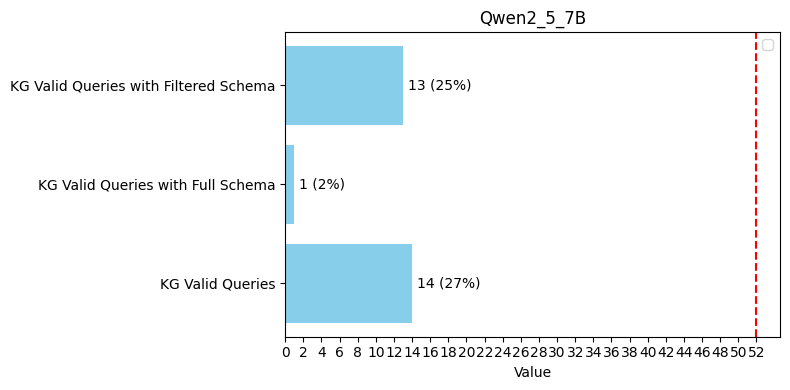

In [ ]:
# kg_valid_queries =  len(kg_valid_queries_df[kg_valid_queries_df['Pass@1 Output']==True])
# kg_valid_queries_with_full_schema = len(kg_valid_queries_with_full_schema_df[kg_valid_queries_with_full_schema_df['Pass@1 Output']==True])
# kg_valid_queries_with_filtered_schema = kg_valid_queries - kg_valid_queries_with_full_schema

# # Data
# values = [kg_valid_queries, kg_valid_queries_with_full_schema, kg_valid_queries_with_filtered_schema]
# labels = ['KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']
# threshold = len(df)

# # Calculate percentages relative to threshold
# percentages = [(v / threshold) * 100 for v in values]

# plt.figure(figsize=(8, 4))
# plt.barh(labels, values, color='skyblue')
# plt.axvline(x=threshold, color='red', linestyle='--')

# # Add combined text: "Value (xx%)"
# for i, (label, value) in enumerate(zip(labels, values)):
#     pct = percentages[i]
#     label_text = f'{value} ({pct:.0f}%)'
#     plt.text(value + 0.5, i, label_text, va='center', fontsize=10)

# # Formatting
# plt.xticks(np.arange(0, len(df) + 2, 2))
# plt.xlabel('Value')
# plt.title(model_name.title())
# plt.legend()
# plt.tight_layout()
# plt.show()
